In [2]:
import os
import shutil 
import torchvision

In [4]:
output_dir = "/home/chiragg21/dev_projects/ml_learning/data/images/Pet_dataset"

total_images_needed = 1000

# 2. Skip completely if the final folder already has files
if os.path.exists(output_dir) and len(os.listdir(output_dir)) > 0:
    print(f"Directory '{output_dir}' already exists and is not empty. Skipping processing.")
else:
    os.makedirs(output_dir, exist_ok=True)

    # 3. Trigger raw download only if the underlying archive doesn't exist
    # Torchvision handles this check internally via download=True
    print("Checking/Downloading raw archive files...")
    train_raw = torchvision.datasets.OxfordIIITPet(root='./raw_data', split='trainval', download=True)
    classes = train_raw.classes

    # 4. Calculate equal images per class
    images_per_class = total_images_needed // len(classes)
    print(f"Extracting exactly {images_per_class} images for each of the {len(classes)} classes...")

    # 5. Initialize counters and class folders
    class_counters = {class_name: 0 for class_name in classes}
    for class_name in classes:
        os.makedirs(os.path.join(output_dir, class_name), exist_ok=True)

    # 6. Extract balanced image set
    raw_images_dir = os.path.join('./raw_data', 'oxford-iiit-pet', 'images')
    all_files = sorted([f for f in os.listdir(raw_images_dir) if f.endswith('.jpg')])
    moved_count = 0

    for filename in all_files:
        class_prefix = filename.rsplit('_', 1)[0]
        
        if class_prefix in classes:
            # Check if this specific class still needs images
            if class_counters[class_prefix] < images_per_class:
                source_file = os.path.join(raw_images_dir, filename)
                destination_file = os.path.join(output_dir, class_prefix, filename)
                
                shutil.copy(source_file, destination_file)
                class_counters[class_prefix] += 1
                moved_count += 1

    print(f"\nSuccess! Extracted {moved_count} total images ({images_per_class} per class) into '{output_dir}'.")


Directory '/home/chiragg21/dev_projects/ml_learning/data/images/Pet_dataset' already exists and is not empty. Skipping processing.


In [5]:
import albumentations as A
import cv2
import matplotlib.pyplot as plt

sample_image_path = output_dir+'/Bengal/Bengal_1.jpg'
sample_image_path

'/home/chiragg21/dev_projects/ml_learning/data/images/Pet_dataset/Bengal/Bengal_1.jpg'

In [6]:
import matplotlib.pyplot as plt
import numpy as np

class PlotImg:
    def __init__(self):
        pass

    def show(self, img, v, h):
        plt.figure(figsize=(v, h))
        plt.imshow(img)
        plt.axis("off")
        plt.show()

    def show_grid(self, images, gx, gy, v, h):
        # 1. Create subplots
        fig, axes = plt.subplots(gx, gy, figsize=(v, h))
        
        # 2. Ensure axes is safely iterable even for 1x1, 1xN, or Nx1 layouts
        if gx == 1 and gy == 1:
            axes = np.array([axes])
        else:
            axes = axes.flatten()

        # 3. Zip through both the axis windows and individual images simultaneously
        for i, ax in enumerate(axes):
            if i < len(images):
                ax.imshow(images[i])   # <-- FIXED: Plotting individual indexed image
            ax.axis('off')             # Cleanly hides empty bounding grids if images < cells

        plt.tight_layout()
        plt.show()

ploter = PlotImg()


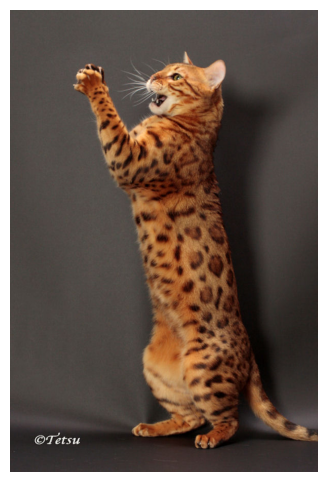

In [8]:
img = cv2.imread(sample_image_path)

if img is None:
    raise FileNotFoundError(f"Could not read image: {sample_image_path}")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

ploter.show(img, 12,6)